Upload your sales_data_sample.csv file


Saving sales_data.csv to sales_data.csv

========== CSV DATA ==========
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           Na

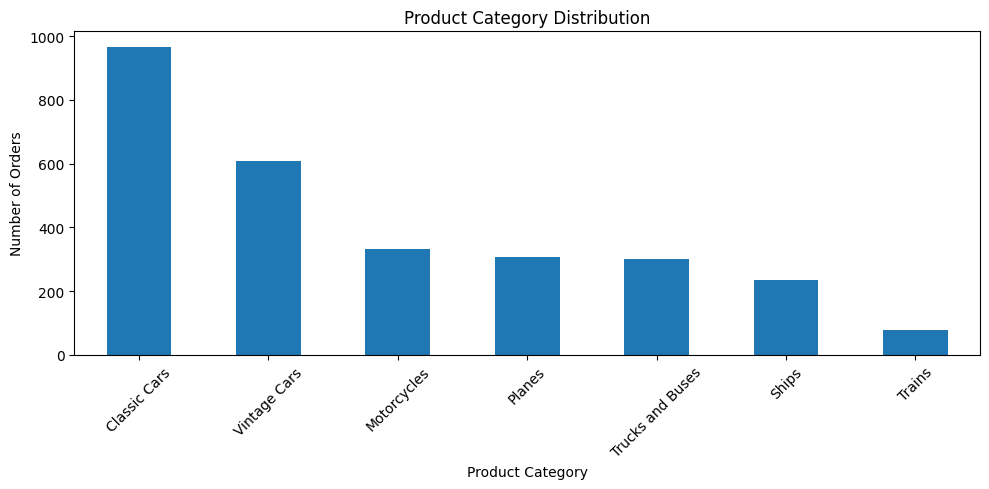

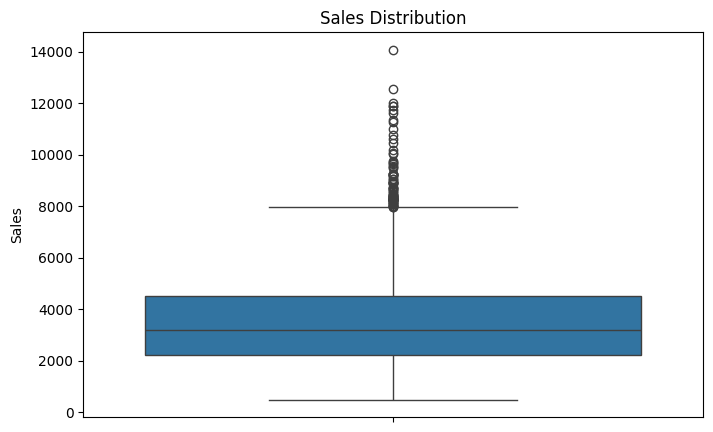

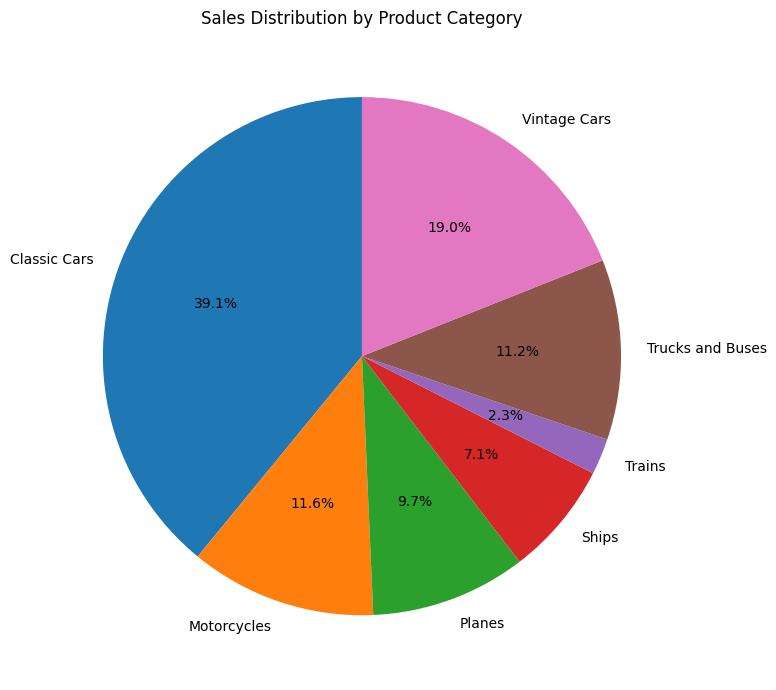


========== EXPERIMENT COMPLETED ==========
Cleaned dataset saved in CSV, Excel and JSON formats.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
#sales data :https://huggingface.co/api/resolve-cache/datasets/adityaswami89/Salesdata/f3048b55b5bc4a760844b7ab6d060cf4ce747f69/sales_data_sample.csv?etag=%22543caea41adecbc6aa894f7db6664bc9f11afd47%22

# ============================================================
# EXPERIMENT NO. 1
# DATA LOADING, STORAGE AND FILE FORMATS
# Analyzing Sales Data from CSV, Excel and JSON
# ============================================================

# STEP 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import os

# STEP 2: Upload the CSV sales dataset
# Upload the file named sales_data_sample.csv

print("Upload your sales_data_sample.csv file")
uploaded = files.upload()

# Get the uploaded CSV filename
csv_file = list(uploaded.keys())[0]

# STEP 3: Load data from CSV format

df_csv = pd.read_csv(csv_file, encoding="latin-1")

print("\n========== CSV DATA ==========")
print(df_csv.head())

# STEP 4: Create Excel and JSON files from the CSV
# This allows us to demonstrate reading all three formats
# using the same sales dataset.

df_csv.to_excel("sales_data_sample.xlsx", index=False)
df_csv.to_json("sales_data_sample.json", orient="records", indent=4)

# STEP 5: Load data from Excel format

df_excel = pd.read_excel("sales_data_sample.xlsx")

print("\n========== EXCEL DATA ==========")
print(df_excel.head())

# STEP 6: Load data from JSON format

df_json = pd.read_json("sales_data_sample.json")

print("\n========== JSON DATA ==========")
print(df_json.head())

# STEP 7: Use CSV data as the main DataFrame
# Convert column names to uppercase for consistency.

df = df_csv.copy()
df.columns = df.columns.str.strip().str.upper()

# STEP 8: Explore the dataset

print("\n========== DATASET INFORMATION ==========")

print("\nFirst 5 rows:")
print(df.head())

print("\nLast 5 rows:")
print(df.tail())

print("\nDataset shape:")
print(df.shape)

print("\nColumn information:")
df.info()

print("\nStatistical description:")
print(df.describe(include="all"))

# STEP 9: Check missing values

print("\n========== MISSING VALUES ==========")
print(df.isnull().sum())

# STEP 10: Remove duplicate records

print("\nDuplicate records:", df.duplicated().sum())

df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

# STEP 11: Clean and handle missing values

# Fill missing numerical values with the column median.
numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

# Fill missing categorical values with the most frequent value.
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    if df[column].isnull().any():
        mode_value = df[column].mode()

        if not mode_value.empty:
            df[column] = df[column].fillna(mode_value[0])
        else:
            df[column] = df[column].fillna("Unknown")

# Remove extra spaces from text columns.
for column in categorical_columns:
    df[column] = df[column].astype(str).str.strip()

print("\nMissing values after cleaning:")
print(df.isnull().sum())

# STEP 12: Convert columns to appropriate data types

# Convert sales-related columns into numeric values.
for column in ["SALES", "PRICEEACH", "QUANTITYORDERED"]:
    if column in df.columns:
        df[column] = pd.to_numeric(df[column], errors="coerce")

# Convert ORDERDATE into datetime format.
if "ORDERDATE" in df.columns:
    df["ORDERDATE"] = pd.to_datetime(
        df["ORDERDATE"], errors="coerce"
    )

# STEP 13: Create a unified DataFrame
# The cleaned CSV data is used as the common DataFrame.

newdf = df.copy()

print("\n========== UNIFIED DATAFRAME ==========")
print(newdf.head())

# STEP 14: Perform data transformation
# Create a LOCATION column by combining CITY and COUNTRY.

if "CITY" in newdf.columns and "COUNTRY" in newdf.columns:
    newdf["LOCATION"] = (
        newdf["CITY"].astype(str) + ", " +
        newdf["COUNTRY"].astype(str)
    )

print("\nData after creating LOCATION:")
print(newdf.head())

# STEP 15: Perform sales analysis

if "SALES" in newdf.columns:

    # Calculate total sales.
    total_sales = newdf["SALES"].sum()

    # Calculate average sales per record.
    avg_order_value = newdf["SALES"].mean()

    print("\n========== SALES ANALYSIS ==========")
    print("Total Sales:", total_sales)
    print("Average Sales:", avg_order_value)

# STEP 16: Analyze product category distribution

if "PRODUCTLINE" in newdf.columns:

    product_category = newdf["PRODUCTLINE"].value_counts()

    print("\n========== PRODUCT CATEGORY ==========")
    print(product_category)

# STEP 17: Visualize product category distribution using a bar chart

if "PRODUCTLINE" in newdf.columns:

    plt.figure(figsize=(10, 5))

    product_category.plot(kind="bar")

    plt.xlabel("Product Category")
    plt.ylabel("Number of Orders")
    plt.title("Product Category Distribution")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# STEP 18: Visualize sales distribution using a box plot

if "SALES" in newdf.columns:

    plt.figure(figsize=(8, 5))

    sns.boxplot(y=newdf["SALES"])

    plt.title("Sales Distribution")
    plt.ylabel("Sales")

    plt.show()

# STEP 19: Visualize sales contribution using a pie chart

if "PRODUCTLINE" in newdf.columns and "SALES" in newdf.columns:

    sales_by_product = newdf.groupby("PRODUCTLINE")["SALES"].sum()

    plt.figure(figsize=(9, 7))

    plt.pie(
        sales_by_product,
        labels=sales_by_product.index,
        autopct="%1.1f%%",
        startangle=90
    )

    plt.title("Sales Distribution by Product Category")
    plt.tight_layout()
    plt.show()

# STEP 20: Save the cleaned dataset in different formats

newdf.to_csv("cleaned_sales_data.csv", index=False)
newdf.to_excel("cleaned_sales_data.xlsx", index=False)
newdf.to_json("cleaned_sales_data.json", orient="records", indent=4)

print("\n========== EXPERIMENT COMPLETED ==========")
print("Cleaned dataset saved in CSV, Excel and JSON formats.")

# Download the cleaned CSV file.
files.download("cleaned_sales_data.csv")
